### Import Library

In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_validate
from sklearn.model_selection import GridSearchCV
from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

### Load Data Label Manual & RoBERTa

In [2]:
MANUAL_PATH = '../../data/labeled/manual_labeling.csv'
ROBERTA_PATH = '../../data/labeled/roberta_labeled.csv'

df_manual = pd.read_csv(MANUAL_PATH, encoding="utf-8-sig")

df_roberta = pd.read_csv(ROBERTA_PATH, encoding="utf-8-sig")

df_manual.columns = df_manual.columns.str.strip()
df_roberta.columns = df_roberta.columns.str.strip()

print("Data manual:", df_manual.shape)
print("Data RoBERTa:", df_roberta.shape)

print("\nKolom manual:")
print(df_manual.columns.tolist())

print("\nKolom RoBERTa:")
print(df_roberta.columns.tolist())

Data manual: (8790, 2)
Data RoBERTa: (48546, 4)

Kolom manual:
['text', 'label']

Kolom RoBERTa:
['text', 'original_text', 'clean_text', 'label_roberta']


### Merapihkan Nama Label

In [3]:
def normalize_label(label):
    label = str(label).strip().lower()

    mapping = {
        "negative": "negative",
        "negatif": "negative",
        "neg": "negative",

        "positive": "positive",
        "positif": "positive",
        "pos": "positive",

        "neutral": "neutral",
        "netral": "neutral",
        "neu": "neutral"
    }

    return mapping.get(label, label)


df_manual["label_manual"] = df_manual["label"].apply(normalize_label)
df_roberta["label_roberta"] = df_roberta["label_roberta"].apply(normalize_label)

print("Distribusi label manual:")
print(df_manual["label_manual"].value_counts())

print("\nDistribusi label roberta:")
print(df_roberta ["label_roberta"].value_counts())

Distribusi label manual:
label_manual
negative    6043
positive    1691
neutral     1056
Name: count, dtype: int64

Distribusi label roberta:
label_roberta
negative    28209
neutral     11228
positive     9109
Name: count, dtype: int64


### Menggabungkan data manual dengan hasil RoBERTa

Karena file label manual berisi 8.790 data, sedangkan RoBERTa berisi 48.546 data, maka bagian yang dibandingkan adalah 8.790 data pertama.

In [4]:
n_manual = len(df_manual)

df_manual_subset = df_manual.copy().reset_index(drop=True)
df_roberta_subset = df_roberta.iloc[:n_manual].copy().reset_index(drop=True)

df_svm_roberta = pd.DataFrame({
    "manual_text": df_manual_subset["text"],
    "clean_text": df_roberta_subset["clean_text"],
    "label_manual": df_manual_subset["label_manual"],
    "label_roberta": df_roberta_subset["label_roberta"]
})

df_svm_roberta["clean_text"] = df_svm_roberta["clean_text"].fillna("").astype(str)
df_svm_roberta = df_svm_roberta[df_svm_roberta["clean_text"].str.strip() != ""]

print("Jumlah data siap pakai:", len(df_svm_roberta))

df_svm_roberta.head()

Jumlah data siap pakai: 8784


,manual_text,clean_text,label_manual,label_roberta
0,adil jokowi,adil jokowi,negative,negative
1,moga pak prabowo tidak kayak begini pak,moga pak prabowo tidak kayak begini pak,neutral,negative
2,siap siap mulyono semua panggil,siap siap mulyono semua panggil,negative,neutral
3,pilih foto biar kesan siapa tuan,pilih foto biar kesan siapa tuan,negative,negative
4,lo bayar nih utang,lo bayar nih utang,negative,neutral


### Menampilkan sampel data hasil penggabungan label manual dan label IndoBERT

In [5]:
df_svm_roberta[[
    "manual_text",
    "clean_text",
    "label_manual",
    "label_roberta"
]].head(20)

,manual_text,clean_text,label_manual,label_roberta
0,adil jokowi,adil jokowi,negative,negative
1,moga pak prabowo tidak kayak begini pak,moga pak prabowo tidak kayak begini pak,neutral,negative
2,siap siap mulyono semua panggil,siap siap mulyono semua panggil,negative,neutral
3,pilih foto biar kesan siapa tuan,pilih foto biar kesan siapa tuan,negative,negative
4,lo bayar nih utang,lo bayar nih utang,negative,neutral
5,ijazah kamu mana wi,ijazah kamu mana wi,negative,negative
6,jangan jadi indonesia pernah tipu satu keluarg...,jangan jadi indonesia pernah tipu satu keluarg...,negative,negative
7,sir kok lebih tarik pinjam bunga lebih tinggi ...,sir kok lebih tarik pinjam bunga lebih tinggi ...,negative,negative
8,waris susah presiden sekarang pak,waris susah presiden sekarang pak,negative,negative
9,halo pak,halo pak,neutral,neutral


### Split Data 80% 20%

In [6]:
X = df_svm_roberta["clean_text"]

y_manual = df_svm_roberta["label_manual"]
y_roberta = df_svm_roberta["label_roberta"]

indices = np.arange(len(df_svm_roberta))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=y_manual
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

# Bagian utama:
# SVM dilatih menggunakan label roberta
y_train = y_roberta.iloc[train_idx]

# SVM diuji menggunakan label manual
y_test = y_manual.iloc[test_idx]

print("Jumlah data train:", len(X_train))
print("Jumlah data test :", len(X_test))

print("\nDistribusi y_train label RoBERTa:")
print(y_train.value_counts())

print("\nDistribusi y_test label manual:")
print(y_test.value_counts())

Jumlah data train: 7027
Jumlah data test : 1757

Distribusi y_train label RoBERTa:
label_roberta
negative    4233
positive    1397
neutral     1397
Name: count, dtype: int64

Distribusi y_test label manual:
label_manual
negative    1208
positive     338
neutral      211
Name: count, dtype: int64


## Pipeline

In [7]:
pipeline = Pipeline([

    (
        "tfidf",
        TfidfVectorizer(
            max_features=10000,
            ngram_range=(1,2),
            min_df=2,
            sublinear_tf=True
        )
    ),

    (
        "oversample",
        RandomOverSampler(
            random_state=42
        )
    ),

    (
        "svm",
        LinearSVC(
            random_state=42
        )
    )

])

# ==========================================================
# GRID SEARCH
# ==========================================================

param_grid = {

    "svm__C":[
        0.01,
        0.1,
        1,
        10,
        100
    ]

}

grid = GridSearchCV(

    estimator=pipeline,

    param_grid=param_grid,

    cv=5,

    scoring="f1_macro",

    n_jobs=-1

)

print("\nTraining model ...")

grid.fit(
    X_train,
    y_train
)

print("\nTraining selesai")

print("\nBest Parameter")
print(grid.best_params_)

print("\nBest Cross Validation Score")
print(grid.best_score_)

# ==========================================================
# MODEL TERBAIK
# ==========================================================

svm_roberta_model = grid.best_estimator_

# ==========================================================
# PREDIKSI
# ==========================================================

y_pred = svm_roberta_model.predict(
    X_test
)




Training model ...

Training selesai

Best Parameter
{'svm__C': 0.1}

Best Cross Validation Score
0.6806958703895204


## Evaluasi



HASIL EVALUASI SVM LABEL ROBERTA (BALANCED DATASET)
Accuracy            : 0.6198
Macro Precision     : 0.5349
Macro Recall        : 0.5689
Macro F1-score      : 0.5301

Weighted Precision  : 0.7090
Weighted Recall     : 0.6198
Weighted F1-score   : 0.6506

Classification Report

              precision    recall  f1-score   support

    negative       0.84      0.66      0.74      1208
     neutral       0.23      0.52      0.32       211
    positive       0.53      0.52      0.52       338

    accuracy                           0.62      1757
   macro avg       0.53      0.57      0.53      1757
weighted avg       0.71      0.62      0.65      1757



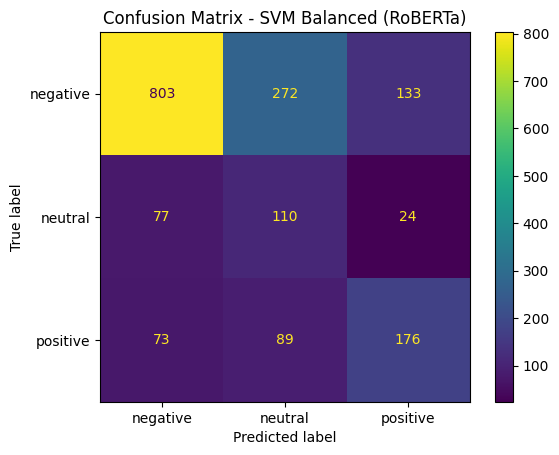

In [8]:
labels_order = [
    "negative",
    "neutral",
    "positive"
]

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision_macro = precision_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

recall_macro = recall_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

f1_macro = f1_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

precision_weighted = precision_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

recall_weighted = recall_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

f1_weighted = f1_score(
    y_test,
    y_pred,
    average="weighted",
    zero_division=0
)

print("\n")
print("="*70)
print("HASIL EVALUASI SVM LABEL ROBERTA (BALANCED DATASET)")
print("="*70)

print(f"Accuracy            : {accuracy:.4f}")
print(f"Macro Precision     : {precision_macro:.4f}")
print(f"Macro Recall        : {recall_macro:.4f}")
print(f"Macro F1-score      : {f1_macro:.4f}")

print()

print(f"Weighted Precision  : {precision_weighted:.4f}")
print(f"Weighted Recall     : {recall_weighted:.4f}")
print(f"Weighted F1-score   : {f1_weighted:.4f}")

print("\nClassification Report\n")

print(
    classification_report(
        y_test,
        y_pred,
        labels=labels_order,
        zero_division=0
    )
)

# ==========================================================
# CONFUSION MATRIX
# ==========================================================

cm = confusion_matrix(

    y_test,

    y_pred,

    labels=labels_order

)

disp = ConfusionMatrixDisplay(

    confusion_matrix=cm,

    display_labels=labels_order

)

disp.plot(values_format="d")

plt.title(
    "Confusion Matrix - SVM Balanced (RoBERTa)"
)

plt.show()



In [9]:
print("="*60)
print("DISTRIBUSI DATA TRAINING")
print("="*60)

print("\nSebelum Oversampling")
print(y_train.value_counts())

tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1,2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(
    X_train
)

ros = RandomOverSampler(
    random_state=42
)

X_balance, y_balance = ros.fit_resample(
    X_train_tfidf,
    y_train
)

print("\nSesudah Oversampling")
print(pd.Series(y_balance).value_counts())

DISTRIBUSI DATA TRAINING

Sebelum Oversampling
label_roberta
negative    4233
positive    1397
neutral     1397
Name: count, dtype: int64

Sesudah Oversampling
label_roberta
positive    4233
neutral     4233
negative    4233
Name: count, dtype: int64
